<a href="https://colab.research.google.com/github/jessicalewinter/deep-learning-specialization/blob/main/course-notebooks/neural-networks/Lab3_Backpropagation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratório 3 — *Backpropagation* em NumPy

**Fundamentos de Redes Neurais Artificiais** · Aula 3

---

### Como vamos usar este notebook

Todo o código está pronto. Vamos executar **uma célula de cada vez**, discutir o que cada uma faz e conferir
os resultados com os slides. Não há nada para completar.

O roteiro acompanha a aula:

1. **Recarregar o Lab 2**: ativações, perdas, inicialização e *forward*, sem nenhuma alteração.
2. **A regra da cadeia num neurônio**: o exemplo dos slides, conferido pela definição de derivada.
3. **O delta da saída**: o cancelamento da softmax com a entropia cruzada, conferido numericamente.
4. **Bloco 1 — O *backward***: as três equações num laço, e a conferência de dimensões.
5. **Os exemplos do quadro**: a rede 2-2-2 desta aula e a rede 2-3-2 da Aula 2.
6. **Bloco 2 — *Gradient checking***: a prova de que o *backward* está certo.
7. **Bloco 3 — Diagnóstico**: quatro bugs colocados de propósito, e a assinatura de cada um.
8. **Experimentos**: a ReLU no gradient check, a escolha de ε e o gradiente que encolhe.
9. **Bloco 4 — A primeira descida**: a rede, pela primeira vez, aprende os dígitos.

O que escrevermos hoje será reaproveitado na Aula 4 sem alteração.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, VERMELHO, VERDE, TINTA = "#7C90B0", "#DB1E2F", "#2E8B8B", "#231F20"
print("pronto")

pronto


## 1. Recarregando o Lab 2

O *backward* é construído em cima do *forward*. A célula abaixo traz, **sem nenhuma alteração**, as funções que
escrevemos na Aula 2. Repare em duas coisas que hoje passam a ser usadas:

- o dicionário `ATIVACOES` guarda uma tupla **(função, derivada)**: hoje usamos o segundo elemento;
- o `forward` devolve o **cache** com todos os `Z` e `A`: hoje é ele que alimenta o *backward*.

In [2]:
# ---------- ativações (Lab 2, Bloco 1)
def sigmoid(Z):
    return 1 / (1 + np.exp(-Z))

def relu(Z):
    return np.maximum(0, Z)

def leaky_relu(Z, alpha=0.01):
    return np.where(Z > 0, Z, alpha * Z)

ATIVACOES = {
    'sigmoid': (sigmoid,    lambda Z: sigmoid(Z) * (1 - sigmoid(Z))),
    'tanh':    (np.tanh,    lambda Z: 1 - np.tanh(Z) ** 2),
    'relu':    (relu,       lambda Z: (Z > 0).astype(float)),       # convenção: derivada 0 em Z = 0
    'leaky':   (leaky_relu, lambda Z: np.where(Z > 0, 1.0, 0.01)),
}

def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)       # estabilidade: o maior logit vira 0
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)    # cada linha soma 1

# ---------- perdas (Lab 2, Bloco 2)
def mse(Y, Y_hat):
    return np.mean((Y - Y_hat) ** 2)

def bce(Y, Y_hat, eps=1e-12):
    Y_hat = np.clip(Y_hat, eps, 1 - eps)
    return -np.mean(Y * np.log(Y_hat) + (1 - Y) * np.log(1 - Y_hat))

def cce(Y, Y_hat, eps=1e-12):                  # Y em one-hot, shape (m, k)
    Y_hat = np.clip(Y_hat, eps, 1.0)
    return -np.mean(np.sum(Y * np.log(Y_hat), axis=1))

def one_hot(y, k):
    Y = np.zeros((len(y), k))
    Y[np.arange(len(y)), y] = 1
    return Y

# ---------- inicialização (Lab 2, Bloco 3)
def inicializa(camadas, escala=0.01, seed=0):
    rng = np.random.default_rng(seed)
    params = {}
    for l in range(1, len(camadas)):
        params[f'W{l}'] = rng.normal(0, escala, (camadas[l-1], camadas[l]))
        params[f'b{l}'] = np.zeros((1, camadas[l]))
    return params

def conta_parametros(params):
    return sum(p.size for p in params.values())

# ---------- forward (Lab 2, Bloco 4)
def forward(X, params, ativacao='relu'):
    g, _ = ATIVACOES[ativacao]          # a função g; a derivada fica para o backward
    L = len(params) // 2                # número de camadas com pesos
    cache = {'A0': X}
    A = X

    for l in range(1, L):               # camadas ocultas
        Z = A @ params[f'W{l}'] + params[f'b{l}']
        A = g(Z)
        cache[f'Z{l}'], cache[f'A{l}'] = Z, A

    ZL = A @ params[f'W{L}'] + params[f'b{L}']   # camada de saída
    AL = softmax(ZL)
    cache[f'Z{L}'], cache[f'A{L}'] = ZL, AL
    return AL, cache

print("funções do Lab 2 carregadas")

funções do Lab 2 carregadas


In [3]:
# conferência rápida: o exemplo 2-3-2 da Aula 2 continua dando 0,0474 e 3,0486
x = np.array([[1.0, -2.0]])
params_232 = {
    'W1': np.array([[ 0.50, -1.00,  0.25],
                    [-0.50,  0.50, -1.00]]),
    'b1': np.array([[ 0.00,  0.50, -0.25]]),
    'W2': np.array([[ 1.00, -1.00],
                    [ 0.50,  0.50],
                    [-2.00,  1.00]]),
    'b2': np.array([[ 0.00,  0.00]]),
}
A2, _ = forward(x, params_232, 'relu')
print("A2 =", A2, "  perda =", round(cce(one_hot(np.array([0]), 2), A2), 4))

A2 = [[0.0474 0.9526]]   perda = 3.0486


## 2. A regra da cadeia num neurônio

O exemplo da Parte 2 dos slides: um neurônio com sigmoid e erro quadrático, uma amostra só.

  z = w·x + b    a = σ(z)    ℒ = (a − y)²

Para trás, cada etapa contribui com **um fator**, a sua derivada local:

  ∂ℒ/∂w = ∂ℒ/∂a · ∂a/∂z · ∂z/∂w = 2(a − y) · a(1 − a) · x

In [4]:
x_n, w_n, b_n, y_n = 1.5, 0.8, -0.2, 1.0

# forward: guardamos cada valor intermediário
z_n = w_n * x_n + b_n
a_n = sigmoid(z_n)
L_n = (a_n - y_n) ** 2
print(f"forward : z = {z_n:.4f}   a = {a_n:.4f}   perda = {L_n:.4f}")

# backward: um fator por etapa, da perda para trás
dL_da = 2 * (a_n - y_n)
da_dz = a_n * (1 - a_n)
dL_dz = dL_da * da_dz
dL_dw = dL_dz * x_n            # ∂z/∂w = x
dL_db = dL_dz * 1.0            # ∂z/∂b = 1
dL_dx = dL_dz * w_n            # ∂z/∂x = w  (a pergunta do slide!)
print(f"backward: dL/da = {dL_da:.4f}   da/dz = {da_dz:.4f}   dL/dz = {dL_dz:.4f}")
print(f"          dL/dw = {dL_dw:.4f}   dL/db = {dL_db:.4f}   dL/dx = {dL_dx:.4f}")

forward : z = 1.0000   a = 0.7311   perda = 0.0723
backward: dL/da = -0.5379   da/dz = 0.1966   dL/dz = -0.1058
          dL/dw = -0.1586   dL/db = -0.1058   dL/dx = -0.0846


### Conferindo pela definição de derivada

Mexemos em `w` um pouquinho para cima e para baixo e medimos quanto a perda muda.
Se a regra da cadeia estiver certa, os dois números coincidem até muitas casas decimais.

In [5]:
def perda_neuronio(w):
    return (sigmoid(w * x_n + b_n) - y_n) ** 2

eps = 1e-4
L_mais, L_menos = perda_neuronio(w_n + eps), perda_neuronio(w_n - eps)
numerico = (L_mais - L_menos) / (2 * eps)

print(f"perda(w + ε) = {L_mais:.8f}")
print(f"perda(w − ε) = {L_menos:.8f}")
print(f"numérico     = {numerico:.8f}")
print(f"analítico    = {dL_dw:.8f}")
print(f"erro relativo: {abs(numerico - dL_dw) / (abs(numerico) + abs(dL_dw)):.1e}")

perda(w + ε) = 0.07231363
perda(w − ε) = 0.07234535
numérico     = -0.15863128
analítico    = -0.15863128
erro relativo: 1.6e-09


### Quando um nó alimenta vários caminhos, as contribuições se **somam**

Um valor `h` entra em duas contas: `z1 = 2h` e `z2 = −h`, e a perda é `ℒ = z1 + 3·z2`.
Pela regra da cadeia multivariada, ∂ℒ/∂h = 1·2 + 3·(−1) = −1.

In [6]:
def perda_h(h):
    z1, z2 = 2 * h, -h
    return z1 + 3 * z2

h, eps = 0.7, 1e-6
print("pela regra da cadeia:", 1 * 2 + 3 * (-1))
print("pela definição      :", round((perda_h(h + eps) - perda_h(h - eps)) / (2 * eps), 6))

pela regra da cadeia: -1
pela definição      : -1.0


## 3. O delta da saída: o cancelamento

### Caso binário: sigmoid com entropia cruzada binária

A derivada da perda traz um denominador ŷ(1 − ŷ); a derivada da sigmoid traz exatamente esse produto
no numerador. Sobra **ŷ − y**. Conferimos numericamente para alguns valores de z.

In [7]:
y_b = 1.0
for z in [-4.0, -1.0, 0.0, 2.0]:
    perda = lambda zz: bce(np.array([[y_b]]), sigmoid(np.array([[zz]])))
    numerico = (perda(z + 1e-6) - perda(z - 1e-6)) / 2e-6
    print(f"z = {z:+.1f}   ŷ = {sigmoid(z):.4f}   numérico = {numerico:+.6f}   ŷ − y = {sigmoid(z) - y_b:+.6f}")

z = -4.0   ŷ = 0.0180   numérico = -0.982014   ŷ − y = -0.982014
z = -1.0   ŷ = 0.2689   numérico = -0.731059   ŷ − y = -0.731059
z = +0.0   ŷ = 0.5000   numérico = -0.500000   ŷ − y = -0.500000
z = +2.0   ŷ = 0.8808   numérico = -0.119203   ŷ − y = -0.119203


### Multiclasse: a jacobiana da softmax

Para uma amostra, a derivada da softmax é uma matriz k×k:

  ∂ŷᵢ/∂zⱼ = ŷᵢ (δᵢⱼ − ŷⱼ)

Cada **linha** dessa matriz soma zero: somar a mesma constante a todos os logits não muda a softmax —
foi a pergunta para casa da Aula 2.

In [8]:
z = np.array([[2.0, 1.0, 0.1]])
s = softmax(z)[0]

J_formula = np.diag(s) - np.outer(s, s)          # ŷᵢ(δᵢⱼ − ŷⱼ)

J_numerica = np.zeros((3, 3))
for j in range(3):
    dz = np.zeros((1, 3)); dz[0, j] = 1e-6
    J_numerica[:, j] = (softmax(z + dz)[0] - softmax(z - dz)[0]) / 2e-6

print("ŷ =", s)
print("jacobiana pela fórmula:\n", J_formula)
print("confere com a numérica?", np.allclose(J_formula, J_numerica, atol=1e-8))
print("soma de cada linha:", J_formula.sum(axis=1))

ŷ = [0.659  0.2424 0.0986]
jacobiana pela fórmula:
 [[ 0.2247 -0.1598 -0.065 ]
 [-0.1598  0.1837 -0.0239]
 [-0.065  -0.0239  0.0889]]
confere com a numérica? True
soma de cada linha: [0. 0. 0.]


### A equação (a): δ⁽ᴸ⁾ = (A⁽ᴸ⁾ − Y) / m

Compondo a jacobiana com o 1/ŷ da entropia cruzada, quase tudo se cancela.
Conferimos para um lote inteiro: derivamos a perda **média** em relação a cada logit, um por um.

In [9]:
rng = np.random.default_rng(0)
m, k = 5, 4
Z_saida = rng.normal(size=(m, k))
Y_lote = one_hot(rng.integers(0, k, m), k)

delta_formula = (softmax(Z_saida) - Y_lote) / m

delta_numerico = np.zeros_like(Z_saida)
for ind in np.ndindex(Z_saida.shape):
    Zp, Zm = Z_saida.copy(), Z_saida.copy()
    Zp[ind] += 1e-6; Zm[ind] -= 1e-6
    delta_numerico[ind] = (cce(Y_lote, softmax(Zp)) - cce(Y_lote, softmax(Zm))) / 2e-6

print("δ pela fórmula:\n", delta_formula)
print("confere com a numérica?", np.allclose(delta_formula, delta_numerico, atol=1e-8))
print("soma de cada linha de δ:", delta_formula.sum(axis=1).round(12))

δ pela fórmula:
 [[ 0.0452 -0.1651  0.0756  0.0443]
 [-0.1859  0.0347  0.089   0.0623]
 [-0.158   0.024   0.0455  0.0885]
 [-0.1883  0.0962  0.0345  0.0576]
 [-0.1795  0.0258  0.0534  0.1003]]
confere com a numérica? True
soma de cada linha de δ: [ 0. -0.  0.  0.  0.]


### Por que não MSE com sigmoid: o gradiente some quando a rede erra com confiança

Rótulo verdadeiro y = 1. Comparamos o gradiente que chega ao logit z com as duas perdas.

In [10]:
print("   ŷ      entropia cruzada: ŷ − y     erro quadrático: 2(ŷ − y)·ŷ(1 − ŷ)")
for p in [0.01, 0.1, 0.5, 0.9]:
    print(f"{p:5.2f}          {p - 1:+.4f}                      {2 * (p - 1) * p * (1 - p):+.4f}")

   ŷ      entropia cruzada: ŷ − y     erro quadrático: 2(ŷ − y)·ŷ(1 − ŷ)
 0.01          -0.9900                      -0.0196
 0.10          -0.9000                      -0.1620
 0.50          -0.5000                      -0.2500
 0.90          -0.1000                      -0.0180


## 4. Bloco 1 — O *backward*

As três equações, aplicadas de trás para frente:

- **(a)** δ⁽ᴸ⁾ = (A⁽ᴸ⁾ − Y) / m
- **(b)** ∂ℒ/∂W⁽ˡ⁾ = (A⁽ˡ⁻¹⁾)ᵀ δ⁽ˡ⁾  e  ∂ℒ/∂b⁽ˡ⁾ = Σᵢ δ⁽ˡ⁾ᵢ
- **(c)** δ⁽ˡ⁻¹⁾ = ( δ⁽ˡ⁾ (W⁽ˡ⁾)ᵀ ) ⊙ g′( Z⁽ˡ⁻¹⁾ )

`A_prev` e `Z{l-1}` vêm do **cache** do *forward*. O `⊙` é o `*` do NumPy (elemento a elemento), não o `@`.

In [11]:
def backward(Y, params, cache, ativacao='relu'):
    _, dg = ATIVACOES[ativacao]          # agora usamos a derivada
    L = len(params) // 2
    m = Y.shape[0]
    grads = {}

    dZ = (cache[f'A{L}'] - Y) / m                    # (a)
    for l in range(L, 0, -1):
        A_prev = cache[f'A{l-1}']
        grads[f'dW{l}'] = A_prev.T @ dZ              # (b)
        grads[f'db{l}'] = dZ.sum(axis=0, keepdims=True)
        if l > 1:                                    # (c)
            dA_prev = dZ @ params[f'W{l}'].T
            dZ = dA_prev * dg(cache[f'Z{l-1}'])
    return grads

### Conferência de dimensões

Regra de ouro: `dW{l}` tem obrigatoriamente o shape de `W{l}`, e `db{l}` o shape de `b{l}`.
Se falhar, falta (ou sobra) uma transposição.

In [12]:
rng = np.random.default_rng(0)
camadas = [4, 5, 3]
m = 7
X_p = rng.normal(size=(m, camadas[0]))
Y_p = one_hot(rng.integers(0, camadas[-1], m), camadas[-1])

params = inicializa(camadas)
AL, cache = forward(X_p, params, 'relu')
grads = backward(Y_p, params, cache, 'relu')

for l in range(1, len(camadas)):
    assert grads[f'dW{l}'].shape == params[f'W{l}'].shape, f'dW{l} com shape errado'
    assert grads[f'db{l}'].shape == params[f'b{l}'].shape, f'db{l} com shape errado'
    print(f"dW{l}: {grads[f'dW{l}'].shape} = W{l}    db{l}: {grads[f'db{l}'].shape} = b{l}")
print("\ndimensões OK")

dW1: (4, 5) = W1    db1: (1, 5) = b1
dW2: (5, 3) = W2    db2: (1, 3) = b2

dimensões OK


In [13]:
# na rede do laboratório, com o lote inteiro: o m some dentro do produto (A_prev.T @ dZ)
params_d = inicializa([64, 32, 10])
X_falso = np.random.default_rng(2).normal(size=(1797, 64))
Y_falso = one_hot(np.random.default_rng(3).integers(0, 10, 1797), 10)
AL, cache = forward(X_falso, params_d, 'relu')
grads = backward(Y_falso, params_d, cache, 'relu')
for nome, g in grads.items():
    print(f"{nome}: {g.shape}")

dW2: (32, 10)
db2: (1, 10)
dW1: (64, 32)
db1: (1, 32)


## 5. O exemplo do quadro: a rede 2-2-2

Duas entradas, duas unidades ocultas com **tanh**, duas saídas com softmax, uma amostra da classe 0.
Se o código não reproduzir os números dos slides, o erro está no código: a conta à mão foi conferida.

In [14]:
x = np.array([[0.5, -1.0]])
Y = np.array([[1.0, 0.0]])                     # classe 0
params_222 = {
    'W1': np.array([[ 0.10, 0.40],
                    [-0.20, 0.30]]),
    'b1': np.array([[ 0.00, 0.10]]),
    'W2': np.array([[ 0.50, -0.30],
                    [ 0.20,  0.80]]),
    'b2': np.array([[ 0.00,  0.00]]),
}

A2, cache = forward(x, params_222, 'tanh')
print("PASSO 1 — forward")
print("  Z1 =", cache['Z1'], "   A1 =", cache['A1'])
print("  Z2 =", cache['Z2'], "   A2 =", A2)
print("  perda =", round(cce(Y, A2), 4))

PASSO 1 — forward
  Z1 = [[0.25 0.  ]]    A1 = [[0.2449 0.    ]]
  Z2 = [[ 0.1225 -0.0735]]    A2 = [[0.5488 0.4512]]
  perda = 0.6


In [15]:
grads = backward(Y, params_222, cache, 'tanh')
print("PASSO 2 — backward")
print("  (a) δ2           =", A2 - Y)
print("  (b) dW2 =\n", grads['dW2'])
print("      db2          =", grads['db2'])
dA1 = (A2 - Y) @ params_222['W2'].T
print("  (c) δ2 · W2ᵀ     =", dA1)
print("      tanh'(Z1)    =", 1 - np.tanh(cache['Z1']) ** 2)
print("      δ1           =", grads['db1'])
print("  (b) dW1 =\n", grads['dW1'])

assert np.allclose(grads['dW2'], [[-0.1105, 0.1105], [0, 0]], atol=1e-4)
assert np.allclose(grads['dW1'], [[-0.1696, 0.1354], [0.3393, -0.2707]], atol=1e-4)
print("\nexemplo à mão reproduzido")

PASSO 2 — backward
  (a) δ2           = [[-0.4512  0.4512]]
  (b) dW2 =
 [[-0.1105  0.1105]
 [-0.      0.    ]]
      db2          = [[-0.4512  0.4512]]
  (c) δ2 · W2ᵀ     = [[-0.3609  0.2707]]
      tanh'(Z1)    = [[0.94 1.  ]]
      δ1           = [[-0.3393  0.2707]]
  (b) dW1 =
 [[-0.1696  0.1354]
 [ 0.3393 -0.2707]]

exemplo à mão reproduzido


### PASSO 3 — um passo de gradiente

O gradiente diz a direção; a taxa de aprendizagem η diz o tamanho do passo. Com η = 0,5:
a probabilidade da classe correta deve subir de 0,549 para 0,757, e a perda cair de 0,600 para 0,278.

In [16]:
eta = 0.5
novos = {k: params_222[k] - eta * grads['d' + k] for k in params_222}
A2_novo, _ = forward(x, novos, 'tanh')
print(f"antes : P(classe 0) = {A2[0, 0]:.4f}   perda = {cce(Y, A2):.4f}")
print(f"depois: P(classe 0) = {A2_novo[0, 0]:.4f}   perda = {cce(Y, A2_novo):.4f}")

antes : P(classe 0) = 0.5488   perda = 0.6000
depois: P(classe 0) = 0.7572   perda = 0.2781


### De volta à rede 2-3-2 da Aula 2: o neurônio desligado

Na Aula 2, a unidade 2 tinha Z = −1,5 e a ReLU a desligou. Prometemos que, no *backprop*, ela receberia
gradiente zero. Conferindo: a **coluna 2** de dW1 e a **linha 2** de dW2 são nulas.

In [17]:
x = np.array([[1.0, -2.0]])
Y = np.array([[1.0, 0.0]])
A2, cache = forward(x, params_232, 'relu')
grads = backward(Y, params_232, cache, 'relu')

print("δ2  =", A2 - Y)
print("δ1  =", grads['db1'], "   <- a unidade 2 recebeu zero")
print("dW2 =\n", grads['dW2'])
print("dW1 =\n", grads['dW1'])

δ2  = [[-0.9526  0.9526]]
δ1  = [[-1.9051  0.      2.8577]]    <- a unidade 2 recebeu zero
dW2 =
 [[-1.4289  1.4289]
 [ 0.      0.    ]
 [-1.9051  1.9051]]
dW1 =
 [[-1.9051  0.      2.8577]
 [ 3.8103  0.     -5.7154]]


## 6. Bloco 2 — *Gradient checking*

Rodar sem erro, ter os shapes certos e até ver a perda cair **não prova** que o *backward* está certo.
A prova independente vem da definição de derivada, pela **diferença central**:

  ∂ℒ/∂θ ≈ [ ℒ(θ + ε) − ℒ(θ − ε) ] / 2ε

Perturbamos **um parâmetro por vez** e comparamos, matriz a matriz, com o analítico, pelo erro relativo:

  erro = ‖ numérico − analítico ‖ / ( ‖ numérico ‖ + ‖ analítico ‖ )

**Critério de aprovação:** erro relativo abaixo de 10⁻⁷, com **tanh** e ε = 10⁻⁶.

In [18]:
def gradient_check(X, Y, params, ativacao='tanh', eps=1e-6, backward_fn=backward):
    AL, cache = forward(X, params, ativacao)
    grads = backward_fn(Y, params, cache, ativacao)

    erros = {}
    for chave, P in params.items():
        numerico = np.zeros_like(P)
        for ind in np.ndindex(P.shape):
            original = P[ind]
            P[ind] = original + eps
            J_mais = cce(Y, forward(X, params, ativacao)[0])
            P[ind] = original - eps
            J_menos = cce(Y, forward(X, params, ativacao)[0])
            P[ind] = original                          # restaurar é essencial
            numerico[ind] = (J_mais - J_menos) / (2 * eps)

        analitico = grads['d' + chave]
        erros[chave] = (np.linalg.norm(numerico - analitico)
                        / (np.linalg.norm(numerico) + np.linalg.norm(analitico)))
    return erros

def relatorio(erros, criterio=1e-7):
    for chave, e in erros.items():
        print(f"  {chave:>3}: erro relativo = {e:.1e}   {'ok' if e < criterio else 'FALHOU'}")
    pior = max(erros.values())
    print("  APROVADO: o backward está correto." if pior < criterio else "  REPROVADO: revise o backward.")
    return pior

In [19]:
params_gc = inicializa([4, 5, 3], escala=1.0, seed=1)
print("rede [4, 5, 3], 7 amostras, tanh, ε = 1e-6")
pior = relatorio(gradient_check(X_p, Y_p, params_gc, 'tanh'))

rede [4, 5, 3], 7 amostras, tanh, ε = 1e-6
   W1: erro relativo = 3.3e-10   ok
   b1: erro relativo = 1.8e-10   ok
   W2: erro relativo = 5.5e-10   ok
   b2: erro relativo = 1.9e-10   ok
  APROVADO: o backward está correto.


## 7. Bloco 3 — Diagnóstico: quatro bugs de propósito

Quando o *gradient check* reprova, o **padrão** do erro diz onde procurar. A função abaixo gera versões
do *backward* com um bug cada, e rodamos o *gradient check* em todas. Compare com a tabela de diagnóstico dos slides.

In [20]:
def backward_com_bug(bug):
    def bw(Y, params, cache, ativacao='relu'):
        _, dg = ATIVACOES[ativacao]
        L = len(params) // 2
        m = Y.shape[0]
        grads = {}
        dZ = (cache[f'A{L}'] - Y) / m
        if bug == 'sinal trocado':        dZ = (Y - cache[f'A{L}']) / m
        if bug == 'm dividido duas vezes': dZ = dZ / m
        if bug == 'sem dividir por m':     dZ = dZ * m
        for l in range(L, 0, -1):
            A_prev = cache[f'A{l-1}']
            grads[f'dW{l}'] = A_prev.T @ dZ
            grads[f'db{l}'] = dZ.sum(axis=0, keepdims=True)
            if l > 1:
                dA_prev = dZ @ params[f'W{l}'].T
                if bug == "esqueceu o g'":
                    dZ = dA_prev                       # falta o ⊙ g'(Z)
                else:
                    dZ = dA_prev * dg(cache[f'Z{l-1}'])
        return grads
    return bw

for bug in ['sinal trocado', "esqueceu o g'", 'm dividido duas vezes', 'sem dividir por m']:
    print(f"\n--- bug: {bug}")
    relatorio(gradient_check(X_p, Y_p, params_gc, 'tanh', backward_fn=backward_com_bug(bug)))


--- bug: sinal trocado
   W1: erro relativo = 1.0e+00   FALHOU
   b1: erro relativo = 1.0e+00   FALHOU
   W2: erro relativo = 1.0e+00   FALHOU
   b2: erro relativo = 1.0e+00   FALHOU
  REPROVADO: revise o backward.

--- bug: esqueceu o g'
   W1: erro relativo = 1.4e-01   FALHOU
   b1: erro relativo = 1.1e-01   FALHOU
   W2: erro relativo = 5.5e-10   ok
   b2: erro relativo = 1.9e-10   ok
  REPROVADO: revise o backward.

--- bug: m dividido duas vezes
   W1: erro relativo = 7.5e-01   FALHOU
   b1: erro relativo = 7.5e-01   FALHOU
   W2: erro relativo = 7.5e-01   FALHOU
   b2: erro relativo = 7.5e-01   FALHOU
  REPROVADO: revise o backward.

--- bug: sem dividir por m
   W1: erro relativo = 7.5e-01   FALHOU
   b1: erro relativo = 7.5e-01   FALHOU
   W2: erro relativo = 7.5e-01   FALHOU
   b2: erro relativo = 7.5e-01   FALHOU
  REPROVADO: revise o backward.


**O que observar.**

| Bug | Assinatura |
|---|---|
| sinal trocado | erro = 1,0 em **todas** as matrizes (o analítico é o numérico com sinal invertido) |
| esqueceu o g′ | `W2` e `b2` passam, só `W1` e `b1` falham: a camada de saída não usa a recursão |
| divisão por m errada | o **mesmo** erro em todas as matrizes: tudo está m vezes maior ou menor |

O quarto bug clássico, esquecer o `keepdims=True` em `db`, nem chega ao *gradient check*: a conferência de
dimensões da Seção 4 acusa antes.

In [21]:
dZ = np.ones((7, 3))
print("com keepdims:", dZ.sum(axis=0, keepdims=True).shape, "  sem keepdims:", dZ.sum(axis=0).shape)

com keepdims: (1, 3)   sem keepdims: (3,)


## 8. Experimentos

### Experimento 1 — a ReLU no *gradient check*

Colocamos uma amostra só de zeros. Com bias zero, todas as pré-ativações dessa amostra caem **exatamente**
em zero — no bico da ReLU. O *backward* está certo; só a ativação muda.

In [22]:
X_bico = X_p.copy()
X_bico[0] = 0.0                                    # Z1 dessa amostra = 0 + b1 = 0

for ativ in ['tanh', 'sigmoid', 'relu']:
    erros = gradient_check(X_bico, Y_p, inicializa([4, 5, 3], escala=1.0, seed=1), ativ)
    pior = max(erros.values())
    print(f"  {ativ:>8}: pior erro = {pior:.1e}   {'aprovado' if pior < 1e-7 else 'REPROVADO'}")
print("\nA ReLU reprova sem que haja bug: em z = 0 a secante tem inclinação 0,5,")
print("mas a derivada usada pelo backward é 0 (pela esquerda) ou 1 (pela direita).")

      tanh: pior erro = 5.4e-10   aprovado
   sigmoid: pior erro = 9.2e-10   aprovado
      relu: pior erro = 1.4e-01   REPROVADO

A ReLU reprova sem que haja bug: em z = 0 a secante tem inclinação 0,5,
mas a derivada usada pelo backward é 0 (pela esquerda) ou 1 (pela direita).


### Experimento 2 — a escolha de ε

Diminuir ε melhora sempre a aproximação? Medimos o erro relativo da rede inteira para ε de 10⁻¹ a 10⁻¹².

  ε = 1e-01:  erro = 3.0e-03
  ε = 1e-02:  erro = 3.1e-05
  ε = 1e-03:  erro = 3.1e-07
  ε = 1e-04:  erro = 3.1e-09
  ε = 1e-05:  erro = 5.0e-11
  ε = 1e-06:  erro = 5.5e-10
  ε = 1e-07:  erro = 4.7e-09
  ε = 1e-08:  erro = 5.7e-08
  ε = 1e-09:  erro = 4.1e-07
  ε = 1e-10:  erro = 5.2e-06
  ε = 1e-11:  erro = 5.0e-05
  ε = 1e-12:  erro = 5.3e-04


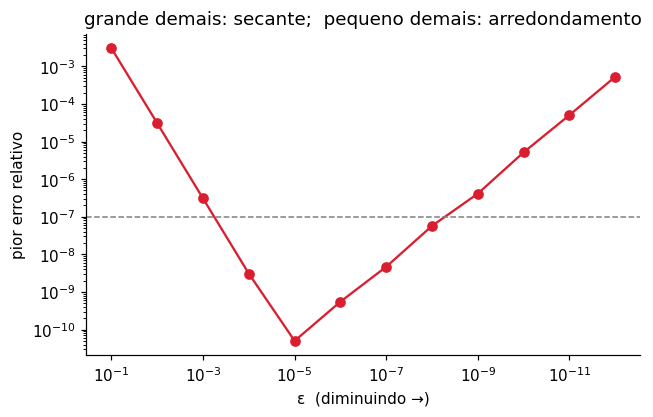

In [23]:
def erro_global(params, eps):
    erros = gradient_check(X_p, Y_p, params, 'tanh', eps=eps)
    return max(erros.values())

lista_eps = 10.0 ** -np.arange(1, 13)
erros_eps = [erro_global(inicializa([4, 5, 3], escala=1.0, seed=1), e) for e in lista_eps]
for e, r in zip(lista_eps, erros_eps):
    print(f"  ε = {e:.0e}:  erro = {r:.1e}")

plt.figure(figsize=(6.5, 3.8))
plt.loglog(lista_eps, erros_eps, "o-", color=VERMELHO)
plt.axhline(1e-7, color="gray", ls="--", lw=1)
plt.gca().invert_xaxis()
plt.xlabel("ε  (diminuindo →)"); plt.ylabel("pior erro relativo")
plt.title("grande demais: secante;  pequeno demais: arredondamento")
plt.show()

### Experimento 3 — o gradiente encolhe ao atravessar camadas

Uma rede com **seis camadas** e a mesma escala de inicialização em todas. Medimos a norma de ∂ℒ/∂W⁽ˡ⁾
em cada camada, para três ativações. É a equação (c) em ação: cada camada multiplica o sinal por g′(Z).

 sigmoid: 1.0e-03  2.4e-03  8.6e-03  3.4e-02  1.4e-01  4.4e-01    última/primeira = 435x
    tanh: 4.6e-01  3.8e-01  3.7e-01  3.3e-01  3.7e-01  3.4e-01    última/primeira = 1x
    relu: 1.8e-01  1.4e-01  1.0e-01  1.1e-01  9.8e-02  8.9e-02    última/primeira = 1x


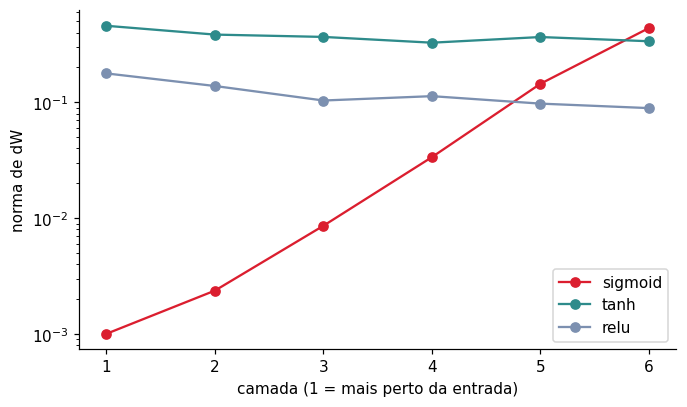

In [24]:
from sklearn.datasets import load_digits
dados = load_digits()
X = dados.data / 16.0
y = dados.target

X_v, Y_v = X[:300], one_hot(y[:300], 10)
arquitetura = [64, 32, 32, 32, 32, 32, 10]

plt.figure(figsize=(7, 4))
for ativ, cor in [('sigmoid', VERMELHO), ('tanh', VERDE), ('relu', AZUL)]:
    params_v = inicializa(arquitetura, escala=0.2, seed=0)
    AL, cache = forward(X_v, params_v, ativ)
    grads = backward(Y_v, params_v, cache, ativ)
    normas = [np.linalg.norm(grads[f'dW{l}']) for l in range(1, 7)]
    print(f"{ativ:>8}:", "  ".join(f"{n:.1e}" for n in normas),
          f"   última/primeira = {normas[-1] / normas[0]:.0f}x")
    plt.semilogy(range(1, 7), normas, "o-", color=cor, label=ativ)
plt.xlabel("camada (1 = mais perto da entrada)"); plt.ylabel("norma de dW")
plt.legend(); plt.show()

## 9. Bloco 4 — A primeira descida

Juntando as peças: *forward*, perda, *backward* e um passo `W ← W − η · dW`, repetido.
É a forma mais simples possível de gradiente descendente — o lote inteiro em cada passo, η fixo.
Como escolher η, usar mini-lotes e inicializar bem é o assunto da Aula 4.

Separamos 25% dos dígitos para **teste**: a rede nunca os vê durante o treino.

In [25]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
Y_tr = one_hot(y_tr, 10)
print("treino:", X_tr.shape, "  teste:", X_te.shape)

def acuracia(X, y, params, ativacao='relu'):
    return np.mean(forward(X, params, ativacao)[0].argmax(axis=1) == y)

treino: (1347, 64)   teste: (450, 64)


In [26]:
params = inicializa([64, 32, 10], seed=0)        # a mesma inicialização do Lab 2
eta, passos = 0.5, 100
hist_perda, hist_acc = [], []

for passo in range(passos + 1):
    AL, cache = forward(X_tr, params, 'relu')
    hist_perda.append(cce(Y_tr, AL))
    hist_acc.append(acuracia(X_te, y_te, params))

    grads = backward(Y_tr, params, cache, 'relu')
    for chave in params:
        params[chave] -= eta * grads['d' + chave]   # o passo do gradiente

    if passo % 25 == 0:
        print(f"passo {passo:>3}:  perda = {hist_perda[-1]:.4f}   acurácia no teste = {hist_acc[-1]:.1%}")

passo   0:  perda = 2.3024   acurácia no teste = 12.4%
passo  25:  perda = 2.2334   acurácia no teste = 48.2%
passo  50:  perda = 1.0928   acurácia no teste = 78.4%
passo  75:  perda = 0.4918   acurácia no teste = 88.7%
passo 100:  perda = 0.3156   acurácia no teste = 91.8%


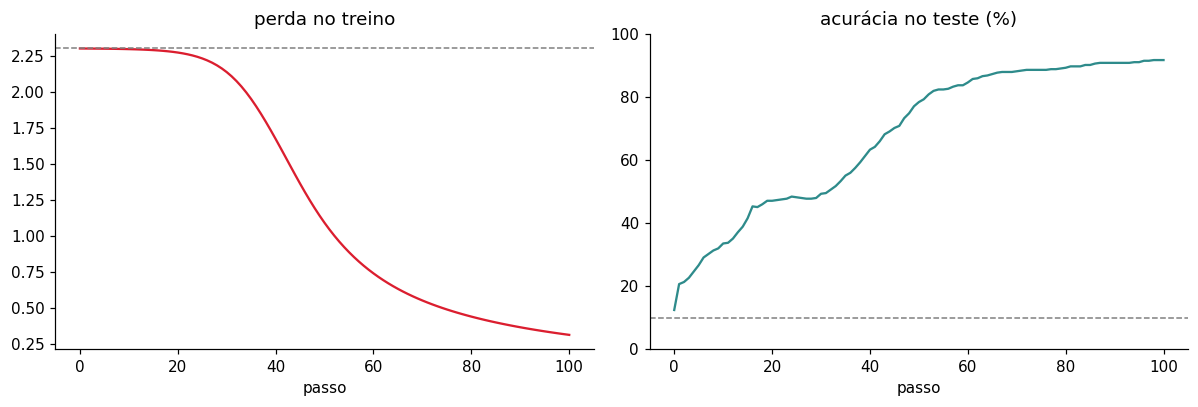

In [27]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(hist_perda, color=VERMELHO); a1.axhline(np.log(10), color="gray", ls="--", lw=1)
a1.set_title("perda no treino"); a1.set_xlabel("passo")
a2.plot(np.array(hist_acc) * 100, color=VERDE); a2.axhline(10, color="gray", ls="--", lw=1)
a2.set_title("acurácia no teste (%)"); a2.set_xlabel("passo"); a2.set_ylim(0, 100)
plt.tight_layout(); plt.show()

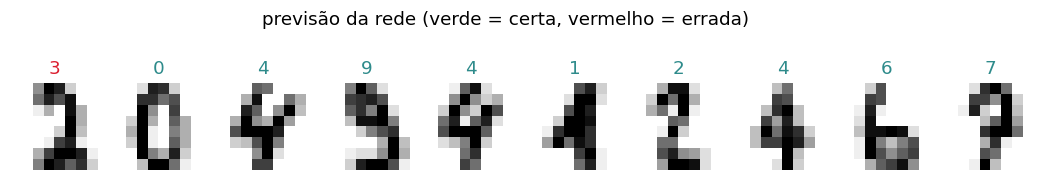

In [28]:
# algumas imagens do teste, com a previsão da rede
prev = forward(X_te, params, 'relu')[0].argmax(axis=1)
fig, axs = plt.subplots(1, 10, figsize=(12, 1.8))
for ax, img, p, v in zip(axs, X_te[:10], prev[:10], y_te[:10]):
    ax.imshow(img.reshape(8, 8), cmap="gray_r"); ax.axis("off")
    ax.set_title(f"{p}", color=VERDE if p == v else VERMELHO)
plt.suptitle("previsão da rede (verde = certa, vermelho = errada)", y=1.08)
plt.show()

**O que observar.** A perda começa em ln 10 ≈ 2,30 — o teste de sanidade da Aula 2 — e passa um bom tempo
quase parada antes de despencar. A acurácia no teste sai dos ~12% do chute e passa de 90% em 100 passos.

Os primeiros passos são lentos porque os pesos começam muito pequenos (escala 0,01): os sinais que
atravessam a rede, para frente e para trás, são minúsculos. A escolha dessa escala é o assunto da Aula 4.

---
## Resumo

- O *backprop* é a regra da cadeia aplicada ao grafo da rede, de trás para frente, reaproveitando o cache.
- δ⁽ˡ⁾ = ∂ℒ/∂Z⁽ˡ⁾ organiza tudo; com softmax e entropia cruzada, δ⁽ᴸ⁾ = (A⁽ᴸ⁾ − Y) / m.
- Cada gradiente tem o shape do parâmetro que ele corrige: `dW = A_prev.T @ dZ`, `db = dZ.sum(axis=0, keepdims=True)`.
- A recursão `dZ = (dZ @ W.T) * dg(Z)` multiplica o sinal por g′ a cada camada: é a origem do gradiente evanescente.
- *Gradient checking* com tanh e ε = 10⁻⁶ é a prova de correção; critério: erro relativo abaixo de 10⁻⁷.
- O padrão do erro aponta o bug: 1,0 em tudo (sinal), só nas primeiras camadas (recursão), igual em tudo (m).

**Na Aula 4:** a linha `params[chave] -= eta * grads[...]` vira o centro da aula — quanto andar, com quantos
exemplos por passo e a partir de que pesos iniciais. E a rede chega a 97% nos dígitos.